# 24 — Week 7: conformal prediction intervals (RQ3)

**Question (RQ3):** can the point forecasts carry calibrated 90% prediction intervals, including at load ramps?

**Design (all choices on validation; test opened once).**
- No model is refit. Intervals are built on the **frozen point forecasts**: validation forecasts stored by notebooks
  07–11 and the Week 4 test forecasts (`reports/week4/test_predictions.parquet`, SHA-256 checked against the Week 4
  freeze record). Seed 0 for multi-seed models.
- Models: `lightgbm_cov` (best overall), `patchtst` (best network on validation), `lightgbm` (univariate; quantum
  reference) and `persistence` (reference for the MPC "naive" scenario).
- Target coverage 90% (α = 0.1). Residuals are used only once their target is observed (delay h).
- Five methods (`src/evaluation/conformal.py`): **static** split conformal; **rolling** window; **ACI** on top of rolling
  (Gibbs and Candès 2021, delayed updates for h = 5 and 15); **Mondrian** windows by a volatility bin (`vol60`) and by
  the model's own predicted change (`mondrian_pc`). Score = |error| / scale with scale ∈ {1, vol60, res60}.
- **Validation protocol:** first half of the validation origins = calibration / warm-up, second half = evaluation.
  **Selection rule (fixed before the screen):** per model, horizon and method, the configuration with the smallest
  mean interval (Winkler) score among those with overall coverage within 0.90 ± 0.02 (if none qualifies: closest
  coverage).
- **Test:** static calibrates on all validation origins; the sequential methods run continuously from the start of
  validation through test (warm start); only test origins are scored.
- Reported: coverage overall / normal / ramp / severe-ramp steps, mean width, interval score, daily coverage, number
  of infinite (ACI) intervals, the α_t trajectory, and the ACI bound check at h = 1 (Prop. 4.1).

**Order:** cells 1–5 (validation only) → cell 6 (freeze record) → cell 7 (**opens the test split once**) → 8–10 → save
(Cmd+S) → cell 11 (export). If `reports/week7/conformal_test_freeze.json` already exists, the test split was already
opened once: cell 6 then writes a second, time-stamped record (report this).


In [1]:
# Cell 1: setup, inputs and integrity checks (validation only)
import sys, json, time, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from evaluation import conformal as CF

HORIZONS = CF.HORIZONS
ALPHA = CF.ALPHA
MODELS = ["lightgbm_cov", "patchtst", "lightgbm", "persistence"]
MAIN = ["lightgbm_cov", "patchtst"]
METHODS = ["static", "rolling", "aci", "mondrian", "mondrian_pc"]
REP, FIG = ROOT / "reports" / "week7", ROOT / "reports" / "figures" / "week7"
REP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
FREEZE_F = REP / "conformal_test_freeze.json"
# categorical slots 1-5 of the reference palette, fixed order = METHODS order
COL = dict(zip(METHODS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6})

md_ = pl.read_parquet(ROOT / "data" / "processed" / "model_dataset.parquet")
meta = json.loads((ROOT / "data" / "processed" / "model_dataset_meta.json").read_text())
V60 = CF.vol60_series(md_)
VAL = CF.load_val(ROOT, MODELS, seed=0)
print("validation forecasts:")
print(VAL.group_by("model", "h").agg(pl.len().alias("n")).sort("model", "h").pivot(on="h", index="model", values="n"))
P = md_["P_kW"].fill_null(np.nan).to_numpy()
FR_VAL = {}
for m in MODELS:
    for h in HORIZONS:
        f = CF.frame(VAL, md_, m, h, V60)
        assert np.allclose(f["y"], P[f["minute"] + h]), (m, h)
        FR_VAL[(m, h)] = f
print("y of every stored forecast equals P(t+h) of the modelling dataset: OK")

def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
w4 = [json.loads(p.read_text()) for p in sorted((ROOT / "reports" / "week4").glob("test_freeze*.json"))]
w4_sha = [r["test_predictions_sha256"] for r in w4 if r.get("test_predictions_sha256")]
TEST_SHA_OK = sha(ROOT / "reports" / "week4" / "test_predictions.parquet") in w4_sha
print("Week 4 test predictions unchanged since their freeze record:", TEST_SHA_OK)
print("conformal freeze record exists:", FREEZE_F.exists(), "(if True, the conformal test run was already done once)")
print(f"configurations per model and horizon: {len(CF.configs())}")


validation forecasts:
shape: (4, 4)
┌──────────────┬───────┬───────┬───────┐
│ model        ┆ 1     ┆ 5     ┆ 15    │
│ ---          ┆ ---   ┆ ---   ┆ ---   │
│ str          ┆ u32   ┆ u32   ┆ u32   │
╞══════════════╪═══════╪═══════╪═══════╡
│ lightgbm     ┆ 42575 ┆ 42567 ┆ 42547 │
│ lightgbm_cov ┆ 42575 ┆ 42567 ┆ 42547 │
│ patchtst     ┆ 42575 ┆ 42567 ┆ 42547 │
│ persistence  ┆ 42575 ┆ 42567 ┆ 42547 │
└──────────────┴───────┴───────┴───────┘
y of every stored forecast equals P(t+h) of the modelling dataset: OK
Week 4 test predictions unchanged since their freeze record: True
conformal freeze record exists: False (if True, the conformal test run was already done once)
configurations per model and horizon: 57


In [2]:
# Cell 2: unit checks of the conformal module on synthetic data (no project data)
rng = np.random.default_rng(0)
n = 40000
minute = np.cumsum(rng.choice([1, 1, 1, 2], n)).astype(np.int64)
sig = np.where(np.arange(n) < n // 2, 0.3, 0.9)                      # variance shift in the middle
e = rng.standard_t(5, n) * sig
SYN = {"minute": minute, "epoch": 1627000000 + 60 * minute, "y": 30 + e, "yhat": np.full(n, 30.0),
       "p0": np.full(n, 30.0), "vol60": sig, "ramp": (np.abs(e) > 2 * sig).astype(float),
       "ramp99": (np.abs(e) > 3 * sig).astype(float)}
iid = {**SYN, "y": 30 + rng.standard_t(5, n) * 0.5, "vol60": np.full(n, 0.5)}
cal, ev = np.arange(n) < n // 4, np.arange(n) >= n // 4
checks = []
_, _, iv = CF.run_config(iid, 1, {"method": "static", "scale": "abs"}, cal)
c = CF.summarise(iid, iv, ev)["cov_all"]; checks.append(("static, exchangeable data: coverage 0.90 +- 0.01", abs(c - 0.9) < 0.01, c))
ev2 = np.arange(n) >= n // 2
_, _, iv = CF.run_config(SYN, 1, {"method": "static", "scale": "abs"}, cal)
c = CF.summarise(SYN, iv, ev2)["cov_all"]; checks.append(("static abs under a variance shift under-covers (< 0.7)", c < 0.7, c))
for h in (1, 15):
    _, r, iv = CF.run_config(SYN, h, {"method": "aci", "scale": "abs", "W": 1440, "gamma": 0.005}, cal)
    k = r["err"] >= 0
    gap, bnd = abs(r["err"][k].mean() - ALPHA), CF.aci_bound(ALPHA, 0.005, r["n_updates"])
    checks.append((f"ACI h={h}: |mean err - alpha| <= Prop. 4.1 bound" + (" (h>1: empirical)" if h > 1 else ""), gap <= bnd, (round(gap, 5), round(bnd, 5))))
    c = CF.summarise(SYN, iv, ev2)["cov_all"]; checks.append((f"ACI h={h}: coverage after the shift 0.90 +- 0.01", abs(c - 0.9) < 0.01, c))
checks.append(("delayed feedback: known_count", CF.known_count(np.array([0, 1, 2, 5, 6, 20]), 5).tolist() == [0, 0, 0, 1, 2, 5], None))
checks.append(("conformal quantile n=99, alpha 0.1 -> 90th value", CF.conformal_q(list(range(1, 100)), 0.1) == (90, 0), None))
checks.append(("alpha_t <= 0 -> infinite, >= 1 -> empty", CF.conformal_q(list(range(100)), 0.0)[1] == 1 and CF.conformal_q(list(range(100)), 1.0)[1] == -1, None))
_, r, _ = CF.run_config(SYN, 1, {"method": "rolling", "scale": "abs", "W": 500}, cal)
i = 20000; known = CF.known_count(SYN["minute"], 1)[i]
win = np.sort(np.abs(SYN["y"] - SYN["yhat"])[known - 500:known])
checks.append(("rolling window = last W known scores (brute force)", np.isclose(r["q"][i], CF.conformal_q(list(win), ALPHA)[0]), None))
for name, ok, val in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  [{val}]" if val is not None else ""))
UNIT_OK = all(ok for _, ok, _ in checks)
print("\nALL UNIT CHECKS PASSED" if UNIT_OK else "\nUNIT CHECKS FAILED: stop and send this output")


PASS  static, exchangeable data: coverage 0.90 +- 0.01  [0.9012666666666667]
PASS  static abs under a variance shift under-covers (< 0.7)  [0.47395]
PASS  ACI h=1: |mean err - alpha| <= Prop. 4.1 bound  [(np.float64(0.0001), 0.00453)]
PASS  ACI h=1: coverage after the shift 0.90 +- 0.01  [0.90005]
PASS  ACI h=15: |mean err - alpha| <= Prop. 4.1 bound (h>1: empirical)  [(np.float64(0.0001), 0.00453)]
PASS  ACI h=15: coverage after the shift 0.90 +- 0.01  [0.9]
PASS  delayed feedback: known_count
PASS  conformal quantile n=99, alpha 0.1 -> 90th value
PASS  alpha_t <= 0 -> infinite, >= 1 -> empty
PASS  rolling window = last W known scores (brute force)

ALL UNIT CHECKS PASSED


In [3]:
# Cell 3: validation screen: every configuration for every model and horizon (about 5-8 min)
assert UNIT_OK
rows = []
t0 = time.time()
CFGS = CF.configs()
for (m, h), f in FR_VAL.items():
    n = len(f["y"])
    cal = np.arange(n) < n // 2                 # first half: calibration / warm-up
    ev = ~cal                                    # second half: evaluation
    for c in CFGS:
        _, r, iv = CF.run_config(f, h, c, cal)
        rows.append({"model": m, "h": h, "method": c["method"], "cfg": CF.cfg_name(c), **CF.summarise(f, iv, ev)})
    print(f"  {m:13s} h={h:>2}: {len(CFGS)} configurations | {time.time() - t0:5.0f} s")
SCREEN = pl.DataFrame(rows)
SCREEN.write_csv(REP / "conformal_val_screen.csv")
print(f"screen: {SCREEN.height} runs -> reports/week7/conformal_val_screen.csv")


  lightgbm_cov  h= 1: 57 configurations |     8 s
  lightgbm_cov  h= 5: 57 configurations |    15 s
  lightgbm_cov  h=15: 57 configurations |    24 s
  patchtst      h= 1: 57 configurations |    32 s
  patchtst      h= 5: 57 configurations |    40 s
  patchtst      h=15: 57 configurations |    47 s
  lightgbm      h= 1: 57 configurations |    55 s
  lightgbm      h= 5: 57 configurations |    63 s
  lightgbm      h=15: 57 configurations |    70 s
  persistence   h= 1: 57 configurations |    78 s
  persistence   h= 5: 57 configurations |    86 s
  persistence   h=15: 57 configurations |    94 s
screen: 684 runs -> reports/week7/conformal_val_screen.csv


In [4]:
# Cell 4: selection on validation (rule fixed in the header) and the ACI bound check
TOL = 0.02
def pick(g):
    ok = g.filter((pl.col("cov_all") - (1 - ALPHA)).abs() <= TOL)
    if ok.height:
        return ok.sort("iscore").row(0, named=True), True
    return g.with_columns((pl.col("cov_all") - (1 - ALPHA)).abs().alias("_d")).sort("_d").row(0, named=True), False
CHOSEN, sel = {}, []
for (m, h, meth), g in SCREEN.group_by("model", "h", "method", maintain_order=True):
    r, ok = pick(g)
    CHOSEN[f"{m}|{h}|{meth}"] = r["cfg"]
    sel.append({**r, "rule_met": ok})
SEL = pl.DataFrame(sel).sort("model", "h", "method")
SEL.write_csv(REP / "conformal_val_selected.csv")
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_width_chars(230)
SHOWC = ["model", "h", "cfg", "rule_met", "cov_all", "cov_normal", "cov_ramp", "cov_severe", "width_all", "iscore",
         "cov_day_min", "n_infinite"]
print(SEL.select(SHOWC).with_columns(pl.col(pl.Float64).round(3)))

def parse(name):
    p = name.split("|")
    c = {"method": p[0], "scale": p[1]}
    for x in p[2:]:
        if x.startswith("W"):
            c["W"] = int(x[1:])
        if x.startswith("g"):
            c["gamma"] = float(x[1:])
    return c

bound_rows = []
for m in MODELS:                                  # Prop. 4.1 on the whole validation run (h = 1 exact; h > 1 empirical)
    for h in HORIZONS:
        c = parse(CHOSEN[f"{m}|{h}|aci"])
        f = FR_VAL[(m, h)]
        _, r, _ = CF.run_config(f, h, c, np.arange(len(f["y"])) < len(f["y"]) // 2)
        k = r["err"] >= 0
        gap, bnd = abs(r["err"][k].mean() - ALPHA), CF.aci_bound(ALPHA, c["gamma"], r["n_updates"])
        bound_rows.append({"model": m, "h": h, "cfg": CHOSEN[f"{m}|{h}|aci"], "T": r["n_updates"],
                           "mean_err": float(r["err"][k].mean()), "gap": gap, "bound": bnd, "within": bool(gap <= bnd)})
BOUND_VAL = pl.DataFrame(bound_rows)
print("\nACI average miscoverage vs Prop. 4.1 bound (validation run; guaranteed only for h = 1):")
print(BOUND_VAL.with_columns(pl.col(pl.Float64).round(5)))
assert BOUND_VAL.filter(pl.col("h") == 1)["within"].all(), "ACI bound violated at h = 1: implementation error"
(REP / "conformal_val.json").write_text(json.dumps({
    "alpha": ALPHA, "models": MODELS, "methods": METHODS, "seed": 0,
    "selection_rule": f"min mean interval score on the 2nd half of validation among configs with |coverage - 0.9| <= {TOL}",
    "chosen": CHOSEN, "grid": {"scales": CF.SCALES, "windows": CF.WINDOWS, "gammas": CF.GAMMAS, "n_bins": CF.N_BINS,
                               "floor_kW": CF.FLOOR, "k_scale": CF.K_SCALE, "min_scores": CF.MIN_SCORES}}, indent=1))
print("\nchosen configurations saved to reports/week7/conformal_val.json")


shape: (60, 12)
┌──────────────┬─────┬──────────────────────────┬──────────┬───┬───────────┬────────┬─────────────┬────────────┐
│ model        ┆ h   ┆ cfg                      ┆ rule_met ┆ … ┆ width_all ┆ iscore ┆ cov_day_min ┆ n_infinite │
│ ---          ┆ --- ┆ ---                      ┆ ---      ┆   ┆ ---       ┆ ---    ┆ ---         ┆ ---        │
│ str          ┆ i64 ┆ str                      ┆ bool     ┆   ┆ f64       ┆ f64    ┆ f64         ┆ i64        │
╞══════════════╪═════╪══════════════════════════╪══════════╪═══╪═══════════╪════════╪═════════════╪════════════╡
│ lightgbm     ┆ 1   ┆ aci|abs|W10080|g0.01     ┆ true     ┆ … ┆ 0.843     ┆ 1.515  ┆ 0.867       ┆ 73         │
│ lightgbm     ┆ 1   ┆ mondrian|vol60|W1440     ┆ true     ┆ … ┆ 0.785     ┆ 1.516  ┆ 0.865       ┆ 0          │
│ lightgbm     ┆ 1   ┆ mondrian_pc|res60|W1440  ┆ true     ┆ … ┆ 0.861     ┆ 1.464  ┆ 0.857       ┆ 0          │
│ lightgbm     ┆ 1   ┆ rolling|res60|W10080     ┆ true     ┆ … ┆ 0.813     ┆ 1.5

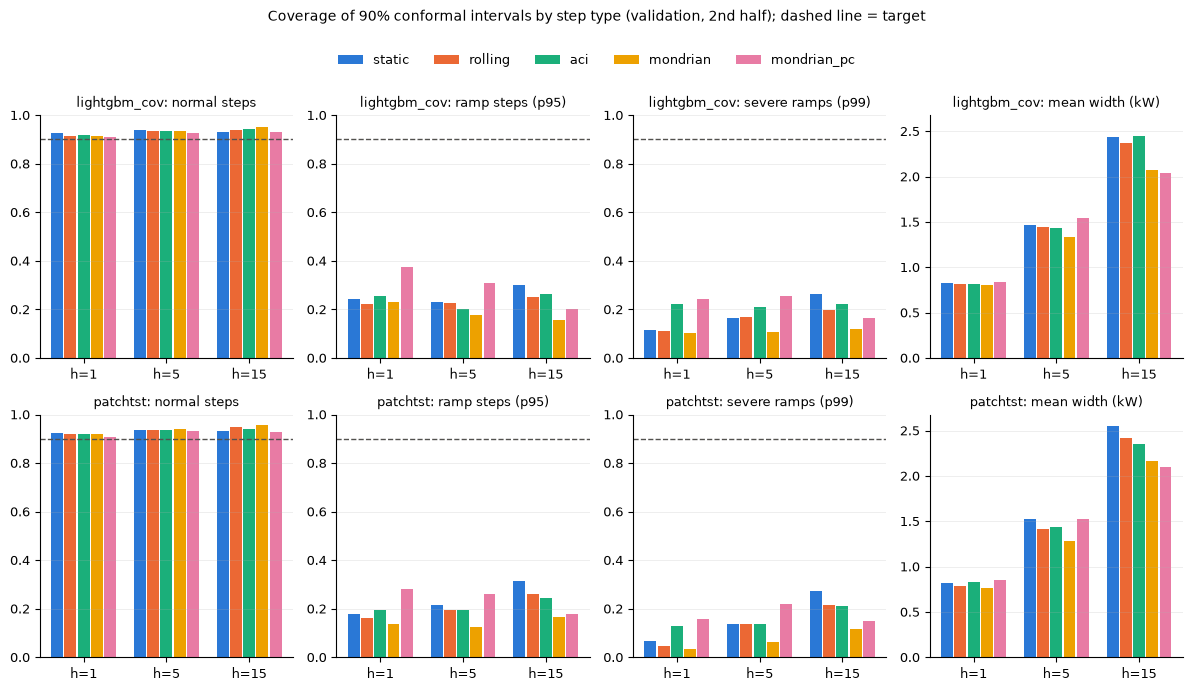

lightgbm_cov: ramp coverage 0.15-0.37 | normal 0.911-0.951 | best ramp coverage by method: static=0.26, rolling=0.23, aci=0.24, mondrian=0.19, mondrian_pc=0.30
patchtst: ramp coverage 0.12-0.31 | normal 0.908-0.958 | best ramp coverage by method: static=0.24, rolling=0.21, aci=0.21, mondrian=0.14, mondrian_pc=0.24


In [5]:
# Cell 5: validation figure: coverage on normal / ramp / severe-ramp steps and mean width per method
def coverage_figure(tab, split_label, fname):
    fig, axes = plt.subplots(len(MAIN), 4, figsize=(12, 3.2 * len(MAIN)), sharey="col")
    cls = [("cov_normal", "normal steps"), ("cov_ramp", "ramp steps (p95)"), ("cov_severe", "severe ramps (p99)")]
    x = np.arange(len(HORIZONS)); wbar = 0.16
    for a, m in enumerate(MAIN):
        for b, (col, lab) in enumerate(cls + [("width_all", "mean width (kW)")]):
            ax = axes[a, b]
            for k, meth in enumerate(METHODS):
                v = [tab.filter((pl.col("model") == m) & (pl.col("h") == h) & (pl.col("method") == meth))[col][0] for h in HORIZONS]
                ax.bar(x + (k - 2) * wbar, v, wbar * 0.9, color=COL[meth], label=meth if (a, b) == (0, 0) else None)
            if col != "width_all":
                ax.axhline(1 - ALPHA, color="#52514e", lw=1, ls="--")
                ax.set_ylim(0, 1)
            ax.set_xticks(x, [f"h={h}" for h in HORIZONS]); ax.grid(axis="x", visible=False)
            ax.set_title(f"{m}: {lab}", fontsize=9)
    fig.legend(loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"Coverage of 90% conformal intervals by step type ({split_label}); dashed line = target", y=1.07, fontsize=10)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=160, bbox_inches="tight"); plt.show()
coverage_figure(SEL, "validation, 2nd half", "01_coverage_by_step_val.png")
for m in MAIN:
    s = SEL.filter(pl.col("model") == m)
    print(f"{m}: ramp coverage {s['cov_ramp'].min():.2f}-{s['cov_ramp'].max():.2f} | normal {s['cov_normal'].min():.3f}-{s['cov_normal'].max():.3f} | "
          f"best ramp coverage by method: " + ", ".join(f"{k}={s.filter(pl.col('method') == k)['cov_ramp'].mean():.2f}" for k in METHODS))


In [6]:
# Cell 6: freeze record (written BEFORE the test split is opened)
assert UNIT_OK and TEST_SHA_OK, "cells 1-2 must pass first"
try:
    git = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip() or None
except Exception:  # noqa: BLE001
    git = None
files = ["reports/week4/test_predictions.parquet", "data/processed/model_dataset.parquet",
         "reports/classical/val_predictions.parquet", "reports/baselines/val_predictions.parquet",
         "experiments/week4_nf/patchtst_s0/predictions_val.parquet", "src/evaluation/conformal.py",
         "reports/week7/conformal_val.json"]
freeze = {"frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "git_head": git,
          "protocol": ["intervals on frozen point forecasts (no refit); seed 0",
                       "configurations chosen on validation (2nd half) with the rule in conformal_val.json",
                       "static: calibration on all validation origins; sequential methods run from the start of validation "
                       "through test, only test origins scored", "one test run; later fixes reported"],
          "alpha": ALPHA, "models": MODELS, "chosen": CHOSEN, "inputs_sha256": {f: sha(ROOT / f) for f in files}}
if FREEZE_F.exists():
    print("NOTE: a conformal freeze record already exists (the test split was opened before); writing a second record")
    FREEZE_F = REP / f"conformal_test_freeze_{time.strftime('%Y%m%d_%H%M%S')}.json"
FREEZE_F.write_text(json.dumps(freeze, indent=1))
print(f"freeze record {FREEZE_F.name} | git {git} | SHA-256 of {len(files)} files")


freeze record conformal_test_freeze.json | git 96597605437198fbfb9cb0a5da4aee2b50ccbbd4 | SHA-256 of 7 files


In [7]:
# Cell 7: OPEN THE TEST SPLIT (once): intervals for the frozen forecasts, chosen configurations
assert FREEZE_F.exists()
TEST = CF.load_test(ROOT, MODELS, seed=0)
rows, parts, ALPHA_TRACE, bound_rows = [], [], {}, []
for m in MODELS:
    for h in HORIZONS:
        fv, ft = FR_VAL[(m, h)], CF.frame(TEST, md_, m, h, V60)
        f, is_test = CF.concat_frames(fv, ft)
        calib = ~is_test
        for meth in METHODS:
            c = parse(CHOSEN[f"{m}|{h}|{meth}"])
            scale, r, iv = CF.run_config(f, h, c, calib)
            rows.append({"model": m, "h": h, "method": meth, "cfg": CHOSEN[f"{m}|{h}|{meth}"], **CF.summarise(f, iv, is_test)})
            k = is_test & iv["have"]
            parts.append(pl.DataFrame({"model": m, "h": h, "method": meth, "minute_epoch": f["epoch"][k], "y": f["y"][k],
                                       "yhat": f["yhat"][k], "lo": iv["lo"][k], "hi": iv["hi"][k],
                                       "covered": iv["covered"][k], "alpha_t": r["alpha_t"][k]}))
            if meth == "aci":
                ALPHA_TRACE[(m, h)] = (f["epoch"], r["alpha_t"], is_test)
                e_ = r["err"] >= 0
                gap, bnd = abs(r["err"][e_].mean() - ALPHA), CF.aci_bound(ALPHA, c["gamma"], r["n_updates"])
                bound_rows.append({"model": m, "h": h, "T": r["n_updates"], "mean_err": float(r["err"][e_].mean()),
                                   "gap": gap, "bound": bnd, "within": bool(gap <= bnd)})
    print(f"  {m}: done")
RES_TEST = pl.DataFrame(rows)
INT_TEST = pl.concat(parts)
INT_TEST.write_parquet(REP / "conformal_test_intervals.parquet")
RES_TEST.write_csv(REP / "conformal_test.csv")
fr = json.loads(FREEZE_F.read_text())
fr["test_opened_at"] = time.strftime("%Y-%m-%d %H:%M:%S")
fr["test_intervals_sha256"] = sha(REP / "conformal_test_intervals.parquet")
FREEZE_F.write_text(json.dumps(fr, indent=1))
BOUND_TEST = pl.DataFrame(bound_rows)
print(f"test intervals: {INT_TEST.height:,} rows | sha256 {fr['test_intervals_sha256'][:16]}...")
print("\nACI bound over the whole validation + test run (h = 1 guaranteed; h > 1 empirical):")
print(BOUND_TEST.with_columns(pl.col(pl.Float64).round(5)))


  lightgbm_cov: done
  patchtst: done
  lightgbm: done
  persistence: done
test intervals: 2,553,780 rows | sha256 2625c2397de79bc8...

ACI bound over the whole validation + test run (h = 1 guaranteed; h > 1 empirical):
shape: (12, 7)
┌──────────────┬─────┬───────┬──────────┬─────────┬─────────┬────────┐
│ model        ┆ h   ┆ T     ┆ mean_err ┆ gap     ┆ bound   ┆ within │
│ ---          ┆ --- ┆ ---   ┆ ---      ┆ ---     ┆ ---     ┆ ---    │
│ str          ┆ i64 ┆ i64   ┆ f64      ┆ f64     ┆ f64     ┆ bool   │
╞══════════════╪═════╪═══════╪══════════╪═════════╪═════════╪════════╡
│ lightgbm_cov ┆ 1   ┆ 85099 ┆ 0.09989  ┆ 0.00011 ┆ 0.00107 ┆ true   │
│ lightgbm_cov ┆ 5   ┆ 85075 ┆ 0.09984  ┆ 0.00016 ┆ 0.00213 ┆ true   │
│ lightgbm_cov ┆ 15  ┆ 85015 ┆ 0.10006  ┆ 0.00006 ┆ 0.0106  ┆ true   │
│ patchtst     ┆ 1   ┆ 85099 ┆ 0.09988  ┆ 0.00012 ┆ 0.00107 ┆ true   │
│ patchtst     ┆ 5   ┆ 85075 ┆ 0.10021  ┆ 0.00021 ┆ 0.01059 ┆ true   │
│ patchtst     ┆ 15  ┆ 85015 ┆ 0.10016  ┆ 0.00016 ┆ 0.0

In [8]:
# Cell 8: test results and validation -> test comparison
print("=== TEST: 90% intervals (seed-0 forecasts) ===")
print(RES_TEST.select(["model", "h", "method", "cov_all", "cov_normal", "cov_ramp", "cov_severe", "width_all", "width_ramp",
                       "iscore", "cov_day_min", "share_days_below_0p8", "n_infinite", "n_ramp", "n_severe"])
      .with_columns(pl.col(pl.Float64).round(3)).sort("model", "h", "method"))
VT = (SEL.select("model", "h", "method", pl.col("cov_all").alias("val_cov"), pl.col("cov_ramp").alias("val_cov_ramp"),
                 pl.col("width_all").alias("val_width"))
         .join(RES_TEST.select("model", "h", "method", pl.col("cov_all").alias("test_cov"), pl.col("cov_ramp").alias("test_cov_ramp"),
                               pl.col("width_all").alias("test_width")), on=["model", "h", "method"])
         .with_columns((pl.col("test_cov") - pl.col("val_cov")).alias("d_cov")))
VT.write_csv(REP / "conformal_val_vs_test.csv")
print("\n=== validation (2nd half) -> test ===")
print(VT.with_columns(pl.col(pl.Float64).round(3)).sort("model", "h", "method"))
best = (RES_TEST.filter((pl.col("cov_all") - 0.9).abs() <= 0.02).sort("iscore").group_by("model", "h", maintain_order=True)
        .first().select("model", "h", "method", "cov_all", "cov_ramp", "width_all", "iscore").sort("model", "h"))
print("\nper model and horizon: smallest test interval score among methods with coverage 0.90 +- 0.02 (reporting only, not a selection):")
print(best.with_columns(pl.col(pl.Float64).round(3)))


=== TEST: 90% intervals (seed-0 forecasts) ===
shape: (60, 15)
┌──────────────┬─────┬─────────────┬─────────┬───┬──────────────────────┬────────────┬────────┬──────────┐
│ model        ┆ h   ┆ method      ┆ cov_all ┆ … ┆ share_days_below_0p8 ┆ n_infinite ┆ n_ramp ┆ n_severe │
│ ---          ┆ --- ┆ ---         ┆ ---     ┆   ┆ ---                  ┆ ---        ┆ ---    ┆ ---      │
│ str          ┆ i64 ┆ str         ┆ f64     ┆   ┆ f64                  ┆ i64        ┆ i64    ┆ i64      │
╞══════════════╪═════╪═════════════╪═════════╪═══╪══════════════════════╪════════════╪════════╪══════════╡
│ lightgbm     ┆ 1   ┆ aci         ┆ 0.9     ┆ … ┆ 0.0                  ┆ 59         ┆ 1659   ┆ 426      │
│ lightgbm     ┆ 1   ┆ mondrian    ┆ 0.898   ┆ … ┆ 0.0                  ┆ 0          ┆ 1659   ┆ 426      │
│ lightgbm     ┆ 1   ┆ mondrian_pc ┆ 0.899   ┆ … ┆ 0.0                  ┆ 0          ┆ 1659   ┆ 426      │
│ lightgbm     ┆ 1   ┆ rolling     ┆ 0.899   ┆ … ┆ 0.0                  ┆ 0      

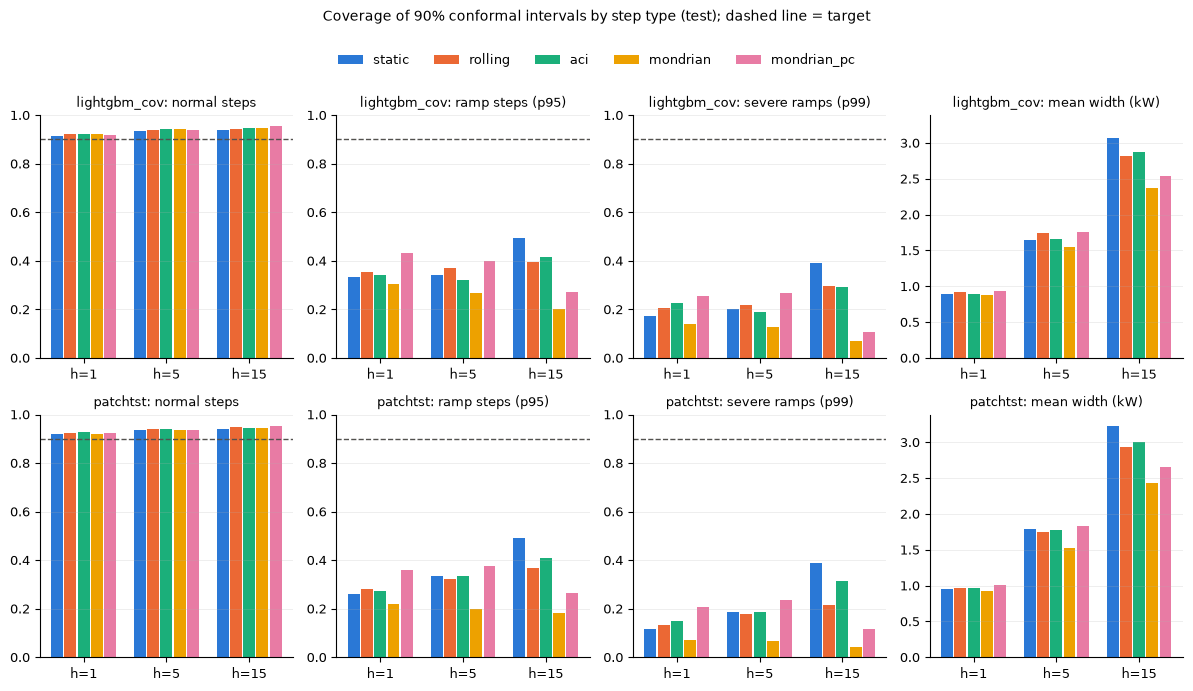

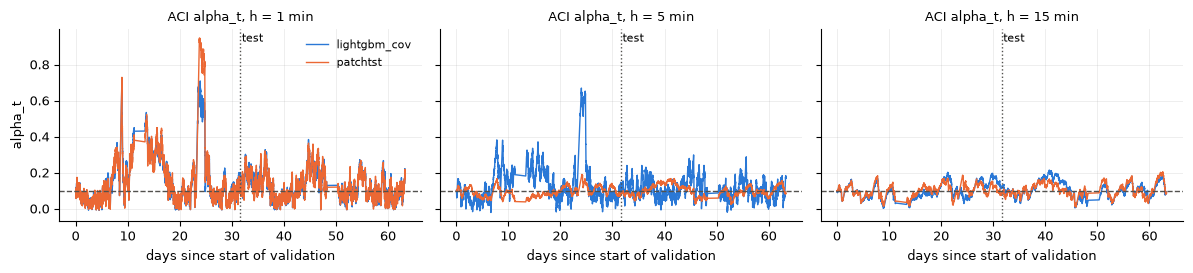

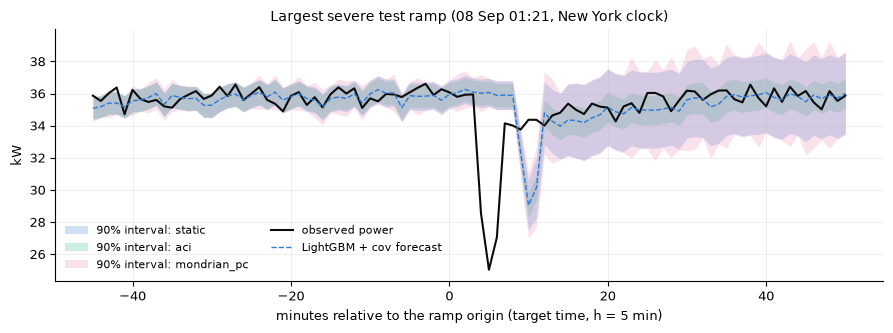

In [9]:
# Cell 9: test figures: coverage by step type; ACI alpha_t trajectory; intervals around a test ramp event
coverage_figure(RES_TEST, "test", "02_coverage_by_step_test.png")

fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, h in zip(axes, HORIZONS):
    for m, colr in (("lightgbm_cov", "#2a78d6"), ("patchtst", "#eb6834")):
        ep, a, te = ALPHA_TRACE[(m, h)]
        ok = np.isfinite(a)
        days = (ep[ok] - ep[0]) / 86400
        ax.plot(days, a[ok], lw=1, color=colr, label=m)
        tstart = (ep[te][0] - ep[0]) / 86400
    ax.axvline(tstart, color="#52514e", lw=1, ls=":"); ax.text(tstart + 0.3, 0.98, "test", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
    ax.axhline(ALPHA, color="#52514e", lw=1, ls="--")
    ax.set_title(f"ACI alpha_t, h = {h} min", fontsize=9); ax.set_xlabel("days since start of validation")
axes[0].set_ylabel("alpha_t"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_aci_alpha_trace.png", dpi=160, bbox_inches="tight"); plt.show()

H_EV = 5
ramp99 = md_[f"ramp99_h{H_EV}"].cast(pl.Float64).fill_null(0).to_numpy()
L24 = md_["L24_kW"].fill_null(np.nan).to_numpy()
g = INT_TEST.filter((pl.col("model") == "lightgbm_cov") & (pl.col("h") == H_EV)).sort("method", "minute_epoch")
ep_all = md_["minute_epoch"].to_numpy()
cand = g.filter(pl.col("method") == "aci")["minute_epoch"].to_numpy()
ti = np.searchsorted(ep_all, cand)
sev = ti[ramp99[ti] == 1]
rel = np.abs(P[sev + H_EV] - P[sev]) / L24[sev]
t_ev = int(sev[np.nanargmax(rel)])
lo_ep, hi_ep = ep_all[t_ev - 45], ep_all[t_ev + 45 + H_EV]
fig, ax = plt.subplots(figsize=(9, 3.4))
w = g.filter((pl.col("minute_epoch") + 60 * H_EV >= lo_ep) & (pl.col("minute_epoch") + 60 * H_EV <= hi_ep))
for meth in ("static", "aci", "mondrian_pc"):
    s = w.filter(pl.col("method") == meth)
    tt = (s["minute_epoch"].to_numpy() + 60 * H_EV - ep_all[t_ev]) / 60
    ax.fill_between(tt, s["lo"].to_numpy(), s["hi"].to_numpy(), color=COL[meth], alpha=0.22, lw=0, label=f"90% interval: {meth}")
s = w.filter(pl.col("method") == "aci")
tt = (s["minute_epoch"].to_numpy() + 60 * H_EV - ep_all[t_ev]) / 60
ax.plot(tt, s["y"].to_numpy(), color="#0b0b0b", lw=1.5, label="observed power")
ax.plot(tt, s["yhat"].to_numpy(), color="#2a78d6", lw=1, ls="--", label="LightGBM + cov forecast")
ax.set_xlabel(f"minutes relative to the ramp origin (target time, h = {H_EV} min)"); ax.set_ylabel("kW")
ax.set_title(f"Largest severe test ramp ({time.strftime('%d %b %H:%M', time.gmtime(ep_all[t_ev]))}, New York clock)", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="best")
fig.tight_layout(); fig.savefig(FIG / "04_ramp_event_intervals_test.png", dpi=160, bbox_inches="tight"); plt.show()


In [10]:
# Cell 10: summary JSON and Week 7 checklist (conformal part)
summ = {"freeze_record": FREEZE_F.name, "alpha": ALPHA, "chosen": CHOSEN,
        "aci_bound_val": BOUND_VAL.to_dicts(), "aci_bound_test_run": BOUND_TEST.to_dicts(),
        "test": RES_TEST.select("model", "h", "method", "cov_all", "cov_normal", "cov_ramp", "cov_severe", "width_all",
                                "iscore", "cov_day_min", "n_infinite").to_dicts(),
        "val": SEL.select("model", "h", "method", "cfg", "cov_all", "cov_normal", "cov_ramp", "cov_severe", "width_all",
                          "iscore").to_dicts()}
(REP / "conformal_summary.json").write_text(json.dumps(summ, indent=1, default=str))
main = RES_TEST.filter(pl.col("model").is_in(MAIN))
chk = [("[main] split conformal on LightGBM and the best network, target 90%", True),
       ("[main] coverage and width reported separately for normal and ramp steps", True),
       ("rolling + ACI with delayed updates (h = 5, 15), alpha_t trajectory, bound check h = 1",
        bool(BOUND_TEST.filter(pl.col("h") == 1)["within"].all())),
       ("test split used once for the conformal group (freeze record)", FREEZE_F.exists())]
for k, v in chk:
    print(f"{'DONE' if v else 'CHECK'}  {k}")
print(f"\ntest coverage range (main models, all methods): {main['cov_all'].min():.3f}-{main['cov_all'].max():.3f}; "
      f"ramp {main['cov_ramp'].min():.3f}-{main['cov_ramp'].max():.3f}; severe {main['cov_severe'].min():.3f}-{main['cov_severe'].max():.3f}")


DONE  [main] split conformal on LightGBM and the best network, target 90%
DONE  [main] coverage and width reported separately for normal and ramp steps
DONE  rolling + ACI with delayed updates (h = 5, 15), alpha_t trajectory, bound check h = 1
DONE  test split used once for the conformal group (freeze record)

test coverage range (main models, all methods): 0.879-0.901; ramp 0.182-0.493; severe 0.042-0.389


In [12]:
# Cell 11: export outputs (save the notebook first with Cmd+S after cell 10 has finished, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 24_week7_conformal.ipynb


written 24_week7_conformal_outputs.md | code cells 12 | figures 4 in 24_week7_conformal_outputs_figures
